# 00 – Audit Dataset
Tujuan: memahami struktur, kualitas, dan duplikasi dataset `theelderemo/genius-lyrics-cleaned`
sebelum menentukan aturan pembersihan, ukuran subset (~100 ribu lagu), dan strategi *chunking*.

Audit dijalankan pada **sampel acak** agar hemat RAM.

Keluaran:
- `songs_subset.parquet` (kolom: `song_id`, `title`, `artist`, `lyrics`)
- `audit_summary.json` (angka-angka untuk laporan)

In [1]:
import os, re, gc, json, hashlib
from collections import Counter
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datasets import load_dataset, concatenate_datasets

# ====== KONFIGURASI ======
SEED         = 42
DATASET_ID   = "theelderemo/genius-lyrics-cleaned"
SAMPLE_N     = 300_000   # audit pada sampel acak ini
SUBSET_SIZE  = 100_000
MIN_WORDS    = 20        # lirik lebih pendek dibuang
MIN_LINES    = 4         # minimal 4 baris agar bisa di-chunk 2-4 baris
MAX_NONLATIN = 0.20      # rasio huruf non-Latin maksimal
OUT_DIR      = "/kaggle/working"

# Isi manual jika deteksi otomatis salah (contoh: LYRIC_COL = "lyrics")
LYRIC_COL, TITLE_COL, ARTIST_COL = None, None, None

tag_re = re.compile(r"\[[^\]]{1,60}\]")   # penanda seperti [Chorus]
summary = {}

## 1. Muat dataset, deteksi kolom, ambil sampel acak

In [2]:
ds = load_dataset(DATASET_ID)
if hasattr(ds, "keys"):
    print("Split:", {k: len(ds[k]) for k in ds.keys()})
    ds = concatenate_datasets([ds[k] for k in ds.keys()])
print("Kolom:", ds.column_names, "| jumlah baris penuh:", len(ds))
summary["n_rows_raw"] = len(ds)
summary["columns"] = ds.column_names

# deteksi kolom dari 1000 baris pertama (murah)
probe = ds.select(range(min(1000, len(ds)))).to_pandas()
display(probe.head(3))
str_cols = [c for c in probe.columns if probe[c].dtype == object]
if LYRIC_COL is None:
    LYRIC_COL = max(str_cols, key=lambda c: probe[c].dropna().astype(str).str.len().mean())
for c in probe.columns:
    cl = c.lower()
    if TITLE_COL is None and "title" in cl:
        TITLE_COL = c
    if ARTIST_COL is None and ("artist" in cl or "singer" in cl):
        ARTIST_COL = c
print("Kolom lirik :", LYRIC_COL)
print("Kolom judul :", TITLE_COL)
print("Kolom artis :", ARTIST_COL)

# sampel acak, hanya kolom yang dipakai
rng = np.random.default_rng(SEED)
n = min(SAMPLE_N, len(ds))
idx = np.sort(rng.choice(len(ds), size=n, replace=False))
keep = [c for c in (LYRIC_COL, TITLE_COL, ARTIST_COL) if c]
df = ds.select(idx).select_columns(keep).to_pandas()
del ds, probe; gc.collect()
summary["n_rows_audited"] = int(len(df))
print("\nBaris yang diaudit:", len(df))

README.md:   0%|          | 0.00/26.1k [00:00<?, ?B/s]

data/train-00000-of-00010.parquet: reconstructing file:   0%|          |  0.00B /  326MB            

data/train-00000-of-00010.parquet: downloading bytes:           |  0.00B            

data/train-00001-of-00010.parquet: reconstructing file:   0%|          |  0.00B /  279MB            

data/train-00001-of-00010.parquet: downloading bytes:           |  0.00B            

data/train-00002-of-00010.parquet: reconstructing file:   0%|          |  0.00B /  258MB            

... (15 outputs left out)

Generating train split:   0%|          | 0/3179588 [00:00<?, ? examples/s]

Split: {'train': 3179588}
Kolom: ['title', 'artist', 'tag', 'year', 'lyrics'] | jumlah baris penuh: 3179588


,title,artist,tag,year,lyrics
0,Rap God,Eminem,rap,2013,"[Intro]\n""Look, I was gonna go easy on you not..."
1,WAP,Cardi B,rap,2020,[Intro]\nWhores in this house\nThere's some wh...
2,Shape of You,Ed Sheeran,pop,2017,[Verse 1]\nThe club isn't the best place to fi...


Kolom lirik : lyrics
Kolom judul : title
Kolom artis : artist

Baris yang diaudit: 300000


## 2. Nilai kosong dan panjang lirik

Nilai kosong per kolom:
lyrics    0
title     7
artist    0
dtype: int64

Lirik kosong/spasi saja: 0


,n_chars,n_words,n_lines
count,300000.0,300000.0,300000.0
mean,1461.5,289.4,44.3
std,1011.3,198.2,27.4
min,101.0,1.0,1.0
1%,197.0,38.0,4.0
5%,402.0,78.0,12.0
25%,815.0,161.0,26.0
50%,1237.0,245.0,40.0
75%,1870.0,372.0,57.0
95%,3215.0,636.0,91.0


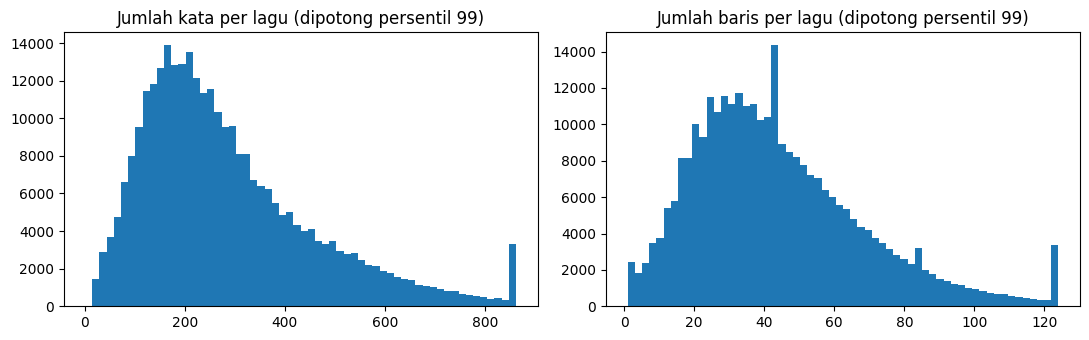

In [3]:
df[LYRIC_COL] = df[LYRIC_COL].fillna("").astype(str)
lyr = df[LYRIC_COL]          # referensi, bukan salinan
print("Nilai kosong per kolom:")
print(df.isna().sum())

df["n_chars"] = lyr.str.len()
df["n_words"] = lyr.str.count(r"\S+")
df["n_lines"] = lyr.str.count(r"(?m)^[ \t]*\S")   # baris tidak kosong

print("\nLirik kosong/spasi saja:", int((lyr.str.strip() == "").sum()))
stats = df[["n_chars", "n_words", "n_lines"]].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(1)
display(stats)
summary["length_stats"] = stats.to_dict()

fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(df["n_words"].clip(upper=df["n_words"].quantile(.99)), bins=60)
ax[0].set_title("Jumlah kata per lagu (dipotong persentil 99)")
ax[1].hist(df["n_lines"].clip(upper=df["n_lines"].quantile(.99)), bins=60)
ax[1].set_title("Jumlah baris per lagu (dipotong persentil 99)")
plt.tight_layout(); plt.show()

## 3. Struktur teks: baris baru, penanda bagian, sisa artefak Genius

In [4]:
has_newline = lyr.str.contains("\n").mean()
has_tag = lyr.str.contains(tag_re).mean()
print(f"Mengandung baris baru       : {has_newline:.1%}")
print(f"Mengandung penanda [Chorus] : {has_tag:.1%}")

# artefak umum Genius
artifacts = {
    "Embed di akhir":        r"\d*Embed\s*$",
    "'You might also like'": r"You might also like",
    "'Contributors'":        r"Contributors?",
    "'Lyrics' di awal":      r"^.{0,80}Lyrics",
}
for name, pat in artifacts.items():
    print(f"{name:25s}: {lyr.str.contains(pat, regex=True).mean():.2%}")

# penanda paling sering (sampel agar cepat)
samp = lyr.sample(min(20000, len(lyr)), random_state=SEED)
tags = Counter(t.lower() for s in samp for t in tag_re.findall(s))
print("\n15 penanda teratas:", tags.most_common(15))

nonascii = lyr.str.contains(r"[^\x00-\x7F]", regex=True).mean()
print(f"\nMengandung karakter non-ASCII: {nonascii:.1%}")

summary["pct_newline"] = float(has_newline)
summary["pct_section_tag"] = float(has_tag)
summary["pct_non_ascii"] = float(nonascii)

Mengandung baris baru       : 99.5%
Mengandung penanda [Chorus] : 47.7%
Embed di akhir           : 0.00%
'You might also like'    : 0.00%
'Contributors'           : 0.00%
'Lyrics' di awal         : 0.33%

15 penanda teratas: [('[chorus]', 13779), ('[verse 1]', 4855), ('[verse 2]', 4624), ('[hook]', 3373), ('[?]', 3268), ('[outro]', 2671), ('[bridge]', 2630), ('[intro]', 2497), ('[pre-chorus]', 2173), ('[verse]', 1547), ('[verse 3]', 1305), ('[post-chorus]', 500), ('[refrain]', 450), ('[verse 4]', 340), ('[interlude]', 323)]

Mengandung karakter non-ASCII: 42.3%


## 4. Bahasa (heuristik) dan duplikasi

In [5]:
# --- rasio huruf non-Latin ---
letters = lyr.str.count(r"[^\W\d_]")
nonlat  = lyr.str.count(r"[^\W\d_a-zA-Z\u00C0-\u024F]")
df["nonlatin"] = (nonlat / letters.replace(0, np.nan)).fillna(1.0)
print("Lirik dengan >20% huruf non-Latin:", int((df["nonlatin"] > MAX_NONLATIN).sum()))

# --- duplikasi ---
def norm(s):
    s = tag_re.sub(" ", s.lower())
    s = re.sub(r"[^a-z0-9\s]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

df["_norm"]   = lyr.apply(norm)
df["_hash"]   = df["_norm"].apply(lambda s: hashlib.md5(s.encode()).hexdigest())
df["_prefix"] = df["_norm"].str[:150]

dup_exact  = int(df.duplicated("_hash").sum())
dup_prefix = int(df[df["_prefix"].str.len() > 50].duplicated("_prefix").sum())
print("Duplikat persis (lirik ternormalisasi):", dup_exact)
print("Duplikat dari 150 karakter awal       :", dup_prefix, "(indikasi versi remix/live)")

if TITLE_COL and ARTIST_COL:
    key = df[TITLE_COL].astype(str).str.lower().str.strip() + "||" + \
          df[ARTIST_COL].astype(str).str.lower().str.strip()
    print("Duplikat judul+artis:", int(key.duplicated().sum()))
    summary["dup_title_artist"] = int(key.duplicated().sum())

summary["dup_exact"] = dup_exact
summary["dup_prefix"] = dup_prefix

df.drop(columns=["_prefix"], inplace=True); gc.collect()

Lirik dengan >20% huruf non-Latin: 51
Duplikat persis (lirik ternormalisasi): 328
Duplikat dari 150 karakter awal       : 3259 (indikasi versi remix/live)
Duplikat judul+artis: 0


127

In [6]:
# Opsional. Butuh Internet On. Hanya 3000 lirik, jadi cepat.
try:
    import langdetect
except ImportError:
    !pip -q install langdetect
    import langdetect
from langdetect import detect, DetectorFactory
DetectorFactory.seed = SEED

def safe_detect(s):
    try:
        return detect(s[:500])
    except Exception:
        return "unk"

s3 = lyr.sample(3000, random_state=SEED)
lang_counts = Counter(s3.apply(safe_detect))
print(lang_counts.most_common(8))
summary["lang_sample_top"] = lang_counts.most_common(8)

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
[('en', 2996), ('id', 1), ('af', 1), ('nl', 1), ('fr', 1)]


## 5. Contoh lirik mentah (cek manual)

In [7]:
for i, row in df.sample(3, random_state=SEED).iterrows():
    print("=" * 70)
    if TITLE_COL:  print("JUDUL :", row[TITLE_COL])
    if ARTIST_COL: print("ARTIS :", row[ARTIST_COL])
    print(repr(str(row[LYRIC_COL])[:500]))

JUDUL : Im On One
ARTIS : Wale
"I am not paying no motherfucking retail for Purple Label this Summer\nFolarin\nAmbition\n\n[Verse 1]\nTwo white cups and I got that drank\nTwo dyke jawns but tonight they straight\nRedbox flow and I do not date\nReal G shit I don't use no cape\nI get my cake; I love hip hop\nJ Cole, Don Trip, Drake, Big Sean\nNigga wanna act we can get improv\nBread on me that's a garlic knot\nTats out and my hair long\nLoud shit, Weird noise\nLike B.o.B., Got airplanes\nNot one J got a pair or more\nFolarin bitch releast nigga "
JUDUL : Before Believing
ARTIS : Emmylou Harris
"[Verse 1]\nWinter, summer season is taking over\nIt's quiet like new fallen snow\nI told you summer stories\nBut outside it's getting mighty cold\nI told you everything I could about me\nTold you everything I could\n\n[Verse 2]\nHow would you feel if the world\nWas falling apart around you\nPieces of the sky were falling\nIn your neighbor's yard but not on you\nWouldn't you feel just a little bit 

## 6. Filter, subset, dan penyimpanan
Urutan filter dicatat sebagai "corong" (funnel) agar bisa dilaporkan.

In [8]:
DROP_NEAR_DUP = True   # buang juga duplikat dekat (150 karakter awal sama), simpan yang pertama

funnel = [("sampel diaudit", len(df))]
d = df[lyr.str.strip() != ""];          funnel.append(("lirik tidak kosong", len(d)))
d = d[d["n_words"] >= MIN_WORDS];       funnel.append((f">= {MIN_WORDS} kata", len(d)))
d = d[d["n_lines"] >= MIN_LINES];       funnel.append((f">= {MIN_LINES} baris", len(d)))
d = d[d["nonlatin"] <= MAX_NONLATIN];   funnel.append(("mayoritas huruf Latin", len(d)))
if TITLE_COL:
    d = d[d[TITLE_COL].notna() & (d[TITLE_COL].astype(str).str.strip() != "")]
    funnel.append(("judul tidak kosong", len(d)))
d = d.drop_duplicates("_hash");         funnel.append(("tanpa duplikat persis", len(d)))
if DROP_NEAR_DUP:
    pref = d["_norm"].str[:150]
    is_dup = pref.str.len().gt(50) & pref.duplicated()
    d = d[~is_dup];                     funnel.append(("tanpa duplikat dekat", len(d)))

for name, n_ in funnel:
    print(f"{name:28s}: {n_:>9,}")

n_take = min(SUBSET_SIZE, len(d))
if n_take < SUBSET_SIZE:
    print(f"\nPERINGATAN: hanya {n_take:,} lagu tersedia setelah filter. "
          f"Naikkan SAMPLE_N atau longgarkan filter.")
sub = d.sample(n=n_take, random_state=SEED).reset_index(drop=True)
sub.insert(0, "song_id", np.arange(len(sub)))

out = pd.DataFrame({
    "song_id": sub["song_id"],
    "title":   sub[TITLE_COL].fillna("").astype(str)  if TITLE_COL  else "",
    "artist":  sub[ARTIST_COL].fillna("").astype(str) if ARTIST_COL else "",
    "lyrics":  sub[LYRIC_COL].astype(str),
})
out.to_parquet(f"{OUT_DIR}/songs_subset.parquet", index=False)

summary["funnel"] = funnel
summary["subset_size"] = int(len(out))
summary["seed"] = SEED
summary["drop_near_dup"] = DROP_NEAR_DUP
with open(f"{OUT_DIR}/audit_summary.json", "w") as f:
    json.dump(summary, f, indent=2, default=str)

print("\nTersimpan:", len(out), "lagu")
display(out.head(3))

sampel diaudit              :   300,000
lirik tidak kosong          :   300,000
>= 20 kata                  :   299,894
>= 4 baris                  :   297,497
mayoritas huruf Latin       :   297,446
judul tidak kosong          :   297,439
tanpa duplikat persis       :   297,113
tanpa duplikat dekat        :   294,190

Tersimpan: 100000 lagu


,song_id,title,artist,lyrics
0,0,Once a Fool,Destiny's Child,"[Chorus]\nI was once a fool, too\nI know what ..."
1,1,BalanceD,Nothing at all. leave me alone,...BALANCED\nFuxk these pussies man\nTime to g...
2,2,City Lights,Blutengel,"I see the city lights, they're burning in my e..."


## Catatan keputusan

**Dataset**
- `theelderemo/genius-lyrics-cleaned`: 3.179.588 baris, satu split (`train`).
- Kolom: `title`, `artist`, `tag` (genre), `year`, `lyrics`. Kolom lirik = `lyrics`.
- Audit pada sampel acak 300.000 baris (seed 42); hasilnya dibaca sebagai estimasi untuk dataset penuh.
- Nilai kosong: hanya `title` (7 dari 300.000 baris, ±0,002%) → baris tanpa judul dibuang di tahap filter, karena judul dibutuhkan untuk menampilkan hasil. Tidak ada lirik atau artis kosong.

**Panjang lirik** (median 245 kata / 40 baris; persentil 5–95 = 78–636 kata)
- Filter ≥ 20 kata hanya membuang 106 lagu, dan filter ≥ 4 baris membuang 2.397 lagu.
- Ada pencilan ekstrem (maks 14.717 kata, 3.110 baris) → di notebook 01 periksa jumlah lagu > 1.500 kata, buang jika sedikit agar tidak menghasilkan terlalu banyak *chunk*.

**Struktur teks**
- 99,5% lirik memakai pemisah baris `\n` → pemecahan *chunk* berbasis baris layak dilakukan.
- 47,7% lirik memuat penanda bagian (`[Chorus]`, `[Verse 1]`, `[Hook]`, `[?]`, `[Outro]`, `[Bridge]`, `[Intro]`, dll.) → dibuang di notebook 01, karena pengguna tidak mengetik penanda itu saat mencari.
- Artefak Genius (“Embed”, “You might also like”, “Contributors”) = 0%, jadi tidak perlu dibersihkan. Pola “Lyrics” di awal teks 0,33%, diperiksa manual di notebook 01.
- Ada baris kosong antar bagian dan sebagian lirik diawali teks pengantar sebelum penanda pertama → baris kosong dibuang sebelum *chunking*.
- 42,3% lirik memuat karakter non-ASCII → perlu normalisasi Unicode (tanda kutip melengkung, huruf beraksen, dll.) di notebook 01. Karakter dominan: apostrof/petik melengkung (’ ‘ ´), spasi khusus (U+2005, U+205F, U+200A, U+00A0), huruf Cyrillic "е" (U+0435) yang menyerupai "e" Latin, serta sisa salah-dekode ("â€™"). Semuanya dinormalisasi di notebook 01.

**Bahasa**
- Sampel 3.000 lirik: 2.996 terdeteksi Inggris (99,9%); empat sisanya kemungkinan salah deteksi. Hanya 51 lirik dengan > 20% huruf non-Latin → dibuang. Tidak perlu penyaringan bahasa tambahan.

**Duplikasi**
- Duplikat persis (lirik ternormalisasi): 328 (0,11%) → dibuang.
- Duplikat dekat (150 karakter awal sama): 3.259 (1,1%), indikasi versi remix/live/cover → dibuang, yang pertama dipertahankan. Kemungkinan masih ada duplikat dekat yang berbeda di bagian akhir; ini dicatat sebagai keterbatasan.
- Duplikat judul + artis: 0.

**Corong filter** (sampel 300.000)
300.000 → ... (≥ 20 kata) → ... (≥ 4 baris) → ... (huruf Latin) → ... (judul tidak kosong) → ... (tanpa duplikat persis) → ... (tanpa duplikat dekat). Isi angka dari keluaran sel 15.

**Subset akhir**: 100.000 lagu (seed 42), disimpan sebagai `songs_subset.parquet` (kolom `song_id`, `title`, `artist`, `lyrics`).

**Catatan untuk tahap berikutnya**
- Kueri sintetis (notebook 05) yang potongan liriknya muncul persis pada lebih dari satu lagu dibuang (kueri ambigu), sesuai bagian Metode.
- Aplikasi web hanya menampilkan *snippet* pendek, bukan lirik utuh.

In [9]:
import pandas as pd, unicodedata
from collections import Counter

chk = pd.read_parquet(f"{OUT_DIR}/songs_subset.parquet")
print("Baris:", len(chk), "| song_id unik:", chk["song_id"].is_unique)
print("Judul kosong:", int((chk["title"].str.strip() == "").sum()),
      "| 'None'/'nan':", int(chk["title"].isin(["None", "nan"]).sum()))
print("Lirik kosong:", int((chk["lyrics"].str.strip() == "").sum()))
print("Ukuran berkas (MB):", round(os.path.getsize(f"{OUT_DIR}/songs_subset.parquet") / 1e6, 1))

s = chk["lyrics"].sample(20000, random_state=SEED)
c = Counter(ch for t in s for ch in t if ord(ch) > 127)
print("\nKarakter non-ASCII teratas:")
for ch, n in c.most_common(25):
    print(repr(ch), hex(ord(ch)), unicodedata.name(ch, "?"), n)

Baris: 100000 | song_id unik: True
Judul kosong: 0 | 'None'/'nan': 0
Lirik kosong: 0
Ukuran berkas (MB): 79.6

Karakter non-ASCII teratas:
'’' 0x2019 RIGHT SINGLE QUOTATION MARK 59615
'\u2005' 0x2005 FOUR-PER-EM SPACE 11527
'\u205f' 0x205f MEDIUM MATHEMATICAL SPACE 4500
'е' 0x435 CYRILLIC SMALL LETTER IE 3927
'‘' 0x2018 LEFT SINGLE QUOTATION MARK 1912
'…' 0x2026 HORIZONTAL ELLIPSIS 1292
'“' 0x201c LEFT DOUBLE QUOTATION MARK 1140
'”' 0x201d RIGHT DOUBLE QUOTATION MARK 1105
'—' 0x2014 EM DASH 806
'\xa0' 0xa0 NO-BREAK SPACE 681
'–' 0x2013 EN DASH 434
'´' 0xb4 ACUTE ACCENT 425
'é' 0xe9 LATIN SMALL LETTER E WITH ACUTE 390
'\u200a' 0x200a HAIR SPACE 291
'\u200b' 0x200b ZERO WIDTH SPACE 255
'\x92' 0x92 ? 130
'‚' 0x201a SINGLE LOW-9 QUOTATION MARK 124
'ñ' 0xf1 LATIN SMALL LETTER N WITH TILDE 105
'à' 0xe0 LATIN SMALL LETTER A WITH GRAVE 74
'′' 0x2032 PRIME 70
'â' 0xe2 LATIN SMALL LETTER A WITH CIRCUMFLEX 61
'í' 0xed LATIN SMALL LETTER I WITH ACUTE 60
'€' 0x20ac EURO SIGN 57
'ó' 0xf3 LATIN SMALL